In [8]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


In [9]:
df = pd.read_parquet("../data/cleaned_merged_df.parquet")


In [10]:
# chronic disease prevalance

illnesses = ["ckd", "dm", "stroke", "cancer", "pud"]

prevalence = []

for illness in illnesses:
    present = df[illness].astype(str).str.strip().str.lower().isin(["yes", "1", "true"])
    total_patients = df["pt_id"].nunique()
    patients_with_illness = df.loc[present, "pt_id"].nunique()

    prevalence.append({
        "illness": illness,
        "patients_with_illness": patients_with_illness,
        "prevalence_pct": round(
            patients_with_illness / total_patients * 100, 2
        ) if total_patients else 0
    })

prevalence = pd.DataFrame(prevalence)
prevalence = prevalence.sort_values("prevalence_pct", ascending=False)

prevalence

,illness,patients_with_illness,prevalence_pct
2,stroke,347,23.48
0,ckd,324,21.92
4,pud,168,11.37
1,dm,166,11.23
3,cancer,32,2.17


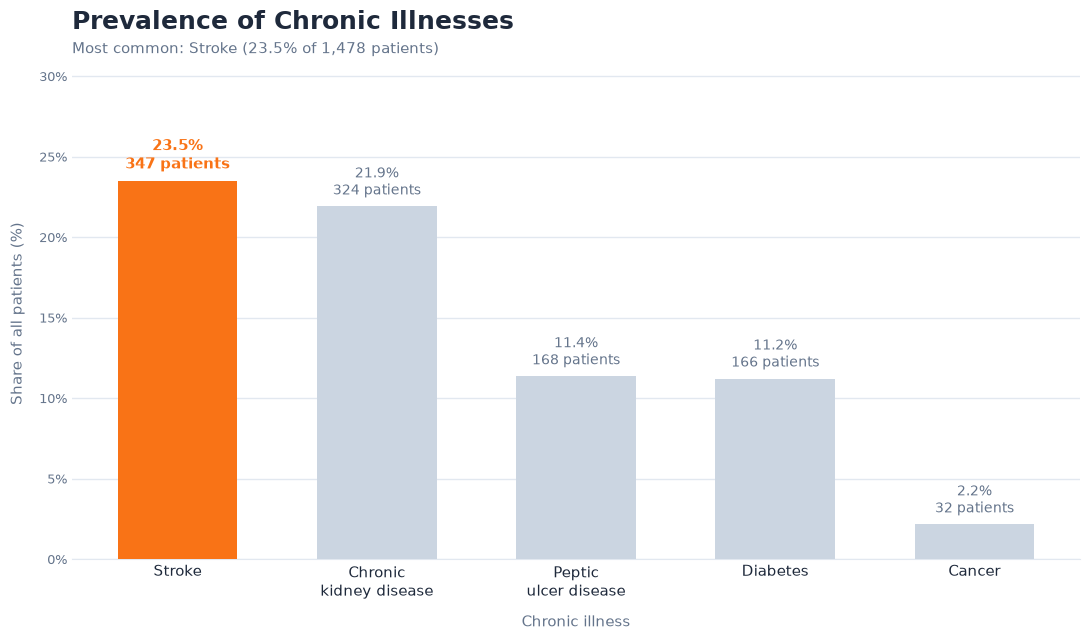

In [11]:

# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# Readable names for the column codes (edit or add yours; unknown codes are shown as-is)
NAMES = {
    "ckd": "Chronic kidney disease",
    "dm": "Diabetes",
    "stroke": "Stroke",
    "cancer": "Cancer",
    "pud": "Peptic ulcer disease",
}

# ---------------- Prep ----------------
data = prevalence.sort_values("prevalence_pct", ascending=False).reset_index(drop=True)
labels = [NAMES.get(i, i.upper()) for i in data["illness"]]
labels = [l.replace(" ", "\n", 1) if len(l) > 12 else l for l in labels]   # wrap long names
pcts   = data["prevalence_pct"]
counts = data["patients_with_illness"]

total_patients = df["pt_id"].nunique()
hi = 0   # sorted, so the first one is the most common

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(max(9, len(data) * 1.8 + 2), 6.5))
fig.patch.set_facecolor("white")

colors = [PEAK if i == hi else BASE for i in range(len(data))]
bars = ax.bar(labels, pcts, color=colors, width=0.6, zorder=3)

# Labels: prevalence on top, patient count underneath
t = ax.bar_label(bars,
                 labels=[f"{p:.1f}%\n{c:,} patients" for p, c in zip(pcts, counts)],
                 padding=5, fontsize=10, color=MUTED, linespacing=1.3)
t[hi].set_color(PEAK)
t[hi].set_fontweight("bold")
t[hi].set_fontsize(11)

# Titles
top_name = NAMES.get(data["illness"].iloc[hi], data["illness"].iloc[hi].upper())
ax.set_title("Prevalence of Chronic Illnesses", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Most common: {top_name} ({pcts.iloc[hi]:.1f}% of {total_patients:,} patients)",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Chronic illness", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Share of all patients (%)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, pcts.max() * 1.3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/chronic_illness_prevalence.png", dpi=180)
plt.show()


In [12]:
for illness in illnesses:
    print(f"\n{illness.upper()}")

    print(
        df.groupby(illness)["admission_duration"]
        .agg(["count", "median", "mean"]).reset_index().round(2)
    )


CKD
   ckd  count  median   mean
0   no   1154    10.0  12.87
1  yes    324     9.5  12.77

DM
    dm  count  median   mean
0   no   1312    10.0  12.77
1  yes    166     9.0  13.52

STROKE
  stroke  count  median   mean
0     no   1131    10.0  12.73
1    yes    347    10.0  13.24

CANCER
  cancer  count  median   mean
0     no   1446    10.0  12.90
1    yes     32     7.5  10.81

PUD
   pud  count  median   mean
0   no   1310    10.0  13.13
1  yes    168     9.0  10.65


In [13]:
for illness in illnesses:
    print(f"\n{illness.upper()}")

    print(
        df.groupby(illness)["dead"]
        .agg(
            count="count",
            deaths=lambda x: x.str.lower().eq("yes").sum(),
            death_rate_pct=lambda x: x.str.lower().eq("yes").mean() * 100
        ).reset_index().round(2)
    )


CKD
   ckd  count  deaths  death_rate_pct
0   no   1154     216           18.72
1  yes    324      74           22.84

DM
    dm  count  deaths  death_rate_pct
0   no   1312     239           18.22
1  yes    166      51           30.72

STROKE
  stroke  count  deaths  death_rate_pct
0     no   1131     214           18.92
1    yes    347      76           21.90

CANCER
  cancer  count  deaths  death_rate_pct
0     no   1446     273           18.88
1    yes     32      17           53.12

PUD
   pud  count  deaths  death_rate_pct
0   no   1310     270           20.61
1  yes    168      20           11.90
